<a href="https://colab.research.google.com/github/gbyellewfr/KKA-AVD-Kelompok8/blob/main/KKA_AVD_LatihanPraktikum.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import io

with open('Data Tugas Kelompok.csv', 'r', encoding='utf-8') as f:
    cleaned_lines = [line.strip().strip('"') for line in f if line.strip()]

df = pd.read_csv(io.StringIO('\n'.join(cleaned_lines)))

print("=== 5 BARIS PERTAMA ===")
print(df.head())

print("=== INFO DATASET ===")
print(df.info())

print("=== RINGKASAN STATISTIK ===")
print(df.describe())

print("=== RATA-RATA GAJI BULANAN PER DEPARTEMEN ===")
rata_dept = df.groupby('Department')['MonthlyIncome'].mean()
print(rata_dept.sort_values(ascending=False))

=== 5 BARIS PERTAMA ===
   Age Attrition     BusinessTravel  DailyRate              Department  \
0   41       Yes      Travel_Rarely       1102                   Sales   
1   49        No  Travel_Frequently        279  Research & Development   
2   37       Yes      Travel_Rarely       1373  Research & Development   
3   33        No  Travel_Frequently       1392  Research & Development   
4   27        No      Travel_Rarely        591  Research & Development   

   DistanceFromHome  Education EducationField  EmployeeCount  EmployeeNumber  \
0                 1          2  Life Sciences              1               1   
1                 8          1  Life Sciences              1               2   
2                 2          2          Other              1               4   
3                 3          4  Life Sciences              1               5   
4                 2          1        Medical              1               7   

   ...  RelationshipSatisfaction StandardHours  St

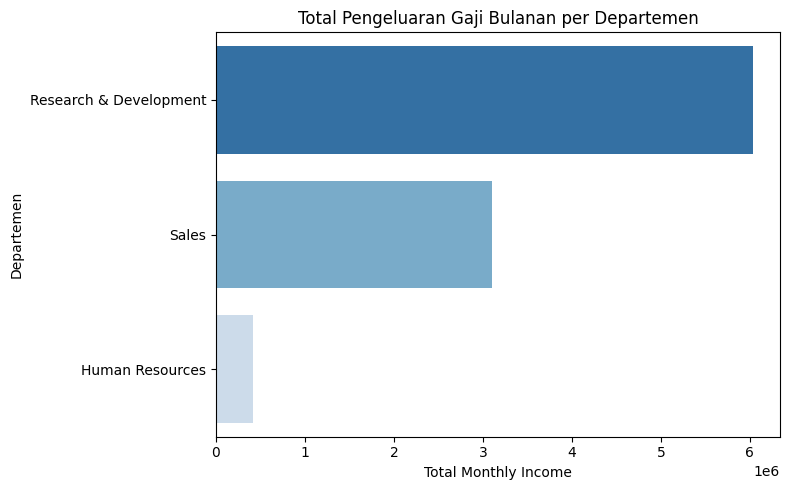

In [12]:
total_dept = df.groupby('Department')['MonthlyIncome'].sum().sort_values(ascending=False)

plt.figure(figsize=(8, 5))
sns.barplot(
    x=total_dept.values,
    y=total_dept.index,
    hue=total_dept.index,
    palette='Blues_r',
    legend=False
)
plt.title('Total Pengeluaran Gaji Bulanan per Departemen')
plt.xlabel('Total Monthly Income')
plt.ylabel('Departemen')
plt.tight_layout()
plt.show()

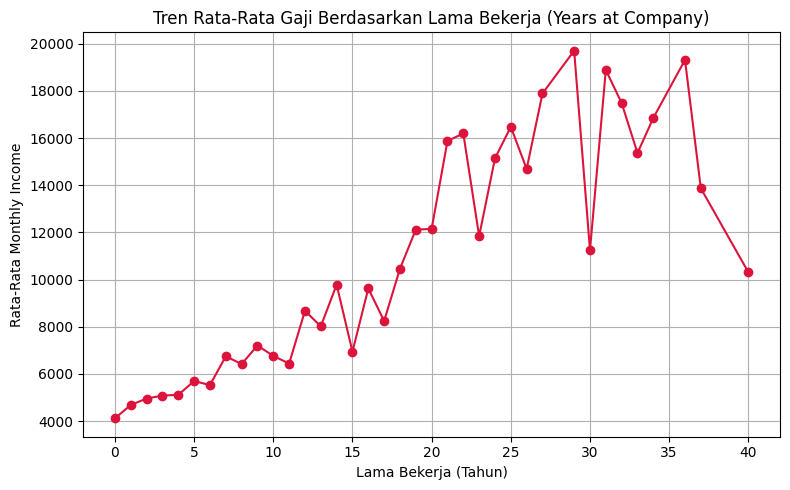

In [13]:
tren_masa_kerja = df.groupby('YearsAtCompany')['MonthlyIncome'].mean()

plt.figure(figsize=(8, 5))
plt.plot(tren_masa_kerja.index, tren_masa_kerja.values, marker='o', color='crimson')
plt.title('Tren Rata-Rata Gaji Berdasarkan Lama Bekerja (Years at Company)')
plt.xlabel('Lama Bekerja (Tahun)')
plt.ylabel('Rata-Rata Monthly Income')
plt.grid(True)
plt.tight_layout()
plt.show()

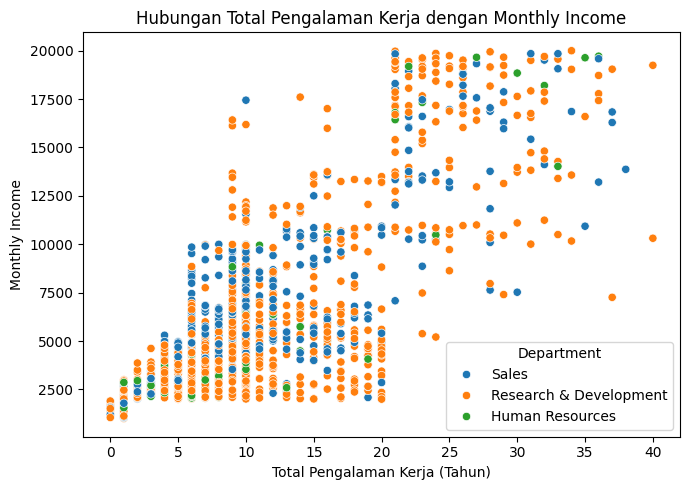

In [14]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x='TotalWorkingYears', y='MonthlyIncome', hue='Department')
plt.title('Hubungan Total Pengalaman Kerja dengan Monthly Income')
plt.xlabel('Total Pengalaman Kerja (Tahun)')
plt.ylabel('Monthly Income')
plt.tight_layout()
plt.show()

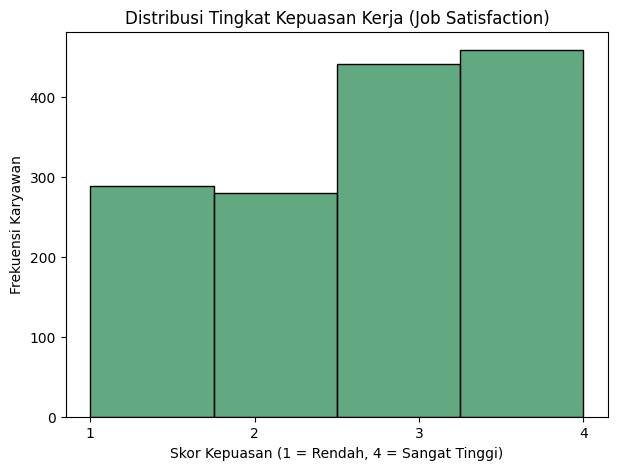

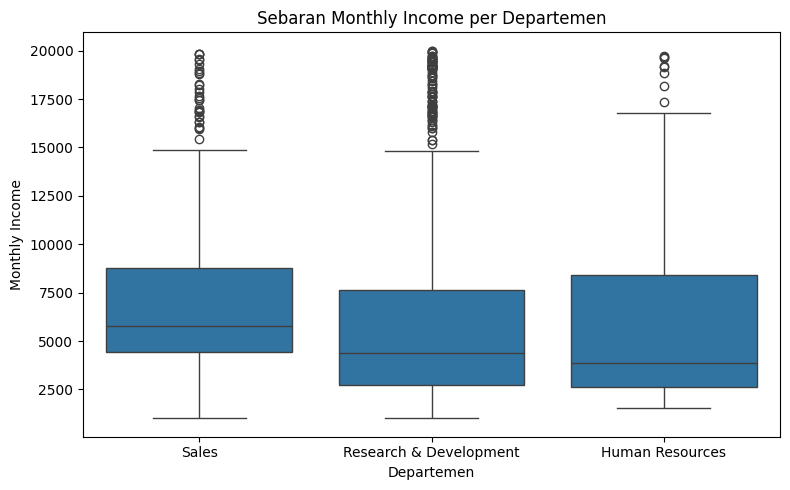

In [15]:
# 1. Histogram distribusi kepuasan kerja
plt.figure(figsize=(7, 5))
sns.histplot(df['JobSatisfaction'], bins=4, color='seagreen')
plt.title('Distribusi Tingkat Kepuasan Kerja (Job Satisfaction)')
plt.xlabel('Skor Kepuasan (1 = Rendah, 4 = Sangat Tinggi)')
plt.ylabel('Frekuensi Karyawan')
plt.xticks([1, 2, 3, 4])
plt.show()

# 2. Boxplot gaji per departemen (deteksi outlier)
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='Department', y='MonthlyIncome')
plt.title('Sebaran Monthly Income per Departemen')
plt.xlabel('Departemen')
plt.ylabel('Monthly Income')
plt.tight_layout()
plt.show()

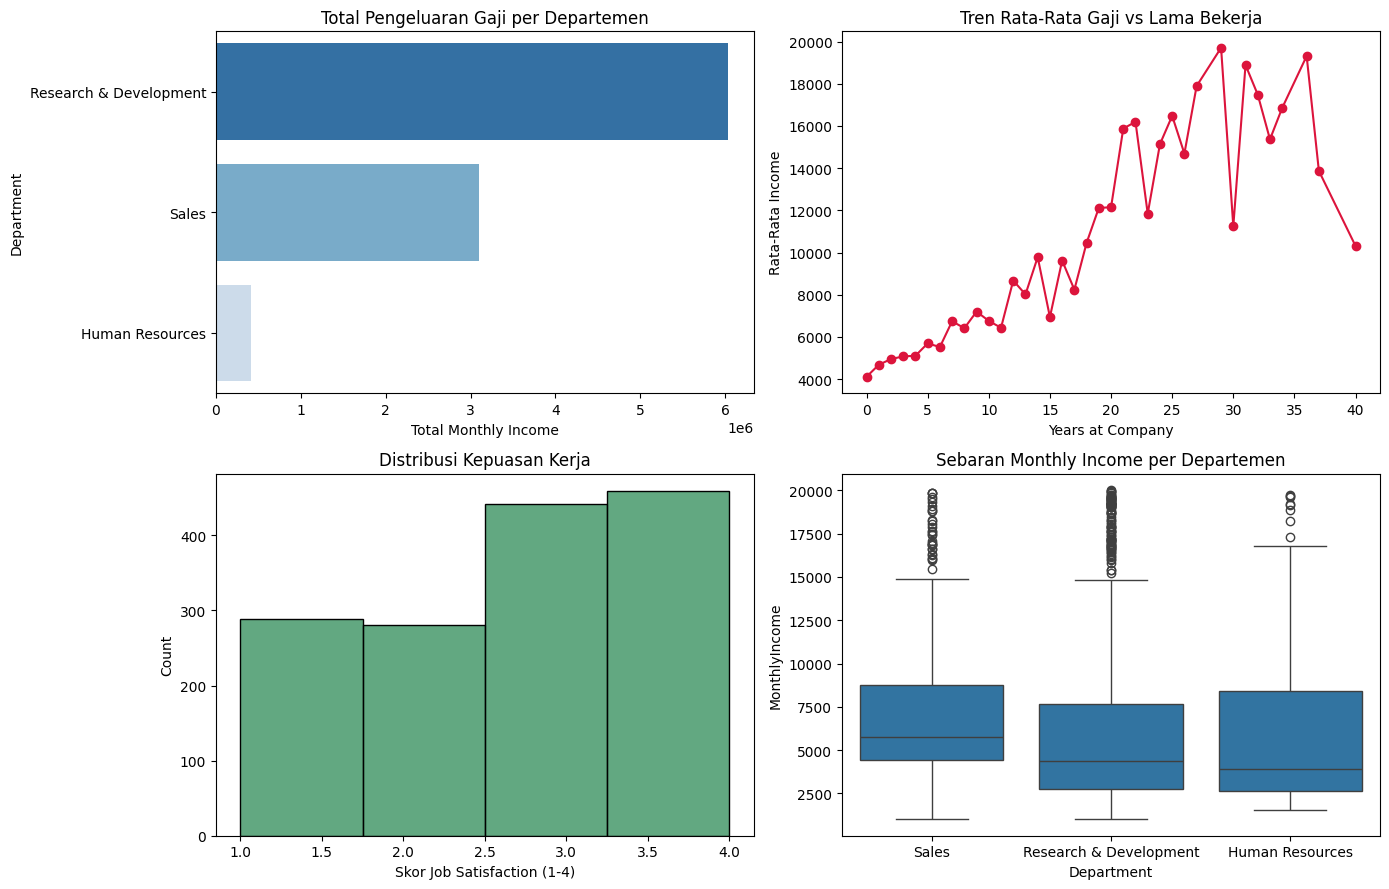

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# 1. Kiri Atas: Bar Chart
sns.barplot(
    x=total_dept.values,
    y=total_dept.index,
    hue=total_dept.index,
    ax=axes[0, 0],
    palette='Blues_r',
    legend=False
)
axes[0, 0].set_title('Total Pengeluaran Gaji per Departemen')
axes[0, 0].set_xlabel('Total Monthly Income')

# 2. Kanan Atas: Line Chart
axes[0, 1].plot(tren_masa_kerja.index, tren_masa_kerja.values, marker='o', color='crimson')
axes[0, 1].set_title('Tren Rata-Rata Gaji vs Lama Bekerja')
axes[0, 1].set_xlabel('Years at Company')
axes[0, 1].set_ylabel('Rata-Rata Income')

# 3. Kiri Bawah: Histogram
sns.histplot(df['JobSatisfaction'], bins=4, ax=axes[1, 0], color='seagreen')
axes[1, 0].set_title('Distribusi Kepuasan Kerja')
axes[1, 0].set_xlabel('Skor Job Satisfaction (1-4)')

# 4. Kanan Bawah: Boxplot
sns.boxplot(data=df, x='Department', y='MonthlyIncome', ax=axes[1, 1])
axes[1, 1].set_title('Sebaran Monthly Income per Departemen')

plt.tight_layout()
plt.show()